# TRƯỜNG ĐẠI HỌC THỦY LỢI
### KHOA CÔNG NGHỆ THÔNG TIN • BỘ MÔN TRÍ TUỆ NHÂN TẠO
## BÀI THỰC HÀNH LAB 5
# SPEECH ENHANCEMENT, SPEAKER RECOGNITION AND SPEAKER SEPARATION
### Từ Khử Nhiễu Trong Miền STFT Đến Xác Định Người Nói Và Tách Hai Nguồn Nói Bằng ICA

---
**Học phần:** CSE457 – Xử lý Âm thanh và Tiếng nói  
**Sinh viên thực hiện:** Nguyễn Văn Đạt  
**Mục tiêu bài thực hành:**
1. **Làm sạch tín hiệu (Speech Enhancement):** Mô hình hóa nhiễu cộng $y[n] = s[n] + v[n]$ tại các mức SNR mục tiêu; biến đổi STFT; ước lượng PSD nhiễu $\hat{P}_v[k]$; cài đặt thuật toán Spectral Subtraction và lọc tối ưu Wiener; phân tích hiện tượng musical noise và méo tiếng; đo đạc $SNR_{out}, \Delta SNR$.
2. **Nhận dạng và xác thực người nói (Speaker Recognition):** Trích xuất MFCC ($D=20$) và $\Delta	ext{MFCC}$; tạo vector biểu diễn người nói (embedding) 80 chiều; so khớp Cosine; đánh giá Speaker Identification (Closed-set) bằng ma trận nhầm lẫn; đánh giá Speaker Verification (Open-set) bằng cách quét ngưỡng $	heta$, đo FAR, FRR và tìm điểm cân bằng EER trên tập Development.
3. **Phân tách nguồn độc lập (BSS / FastICA):** Mô hình hóa 2 nguồn âm thanh quan sát qua 2 microphone $x = A \cdot s$; giải ma trận tách bằng FastICA; giải quyết triệt để 2 bất định Permutation và Sign/Scale bằng tương quan tuyệt đối $|ho|$; khảo sát điều kiện suy biến của ma trận trộn và độ bền vững trước nhiễu.
4. **Tích hợp hệ thống ("Trợ lý phòng họp mini"):** Nối kết liên hoàn 3 mô-đun: Làm sạch câu lệnh bị lẫn tiếng quạt $ightarrow$ Định danh người phát biểu $ightarrow$ Tách hai giọng nói tranh chấp chồng lấn.


---
## BƯỚC 1: KHỞI TẠO MÔI TRƯỜNG & CẤU HÌNH THAM SỐ THÍ NGHIỆM
Toàn bộ tham số hệ thống được gom vào một cell cấu hình duy nhất để đảm bảo tính tái lập 100% kết quả.


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
import librosa
import librosa.display
import IPython.display as ipd
from sklearn.decomposition import FastICA
from sklearn.metrics import confusion_matrix

# Thiết lập đường dẫn
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "lab5_data"
RESULTS_DIR = BASE_DIR / "results"
AUDIO_DIR = RESULTS_DIR / "audio"
FIGS_DIR = RESULTS_DIR / "figures"

AUDIO_DIR.mkdir(parents=True, exist_ok=True)
FIGS_DIR.mkdir(parents=True, exist_ok=True)

# Cấu hình tham số chuẩn hóa (Single Config Cell)
CONFIG = {
    "sr": 16000,
    "n_fft": 512,
    "win_length": 400,     # 25 ms tại 16 kHz
    "hop_length": 160,     # 10 ms tại 16 kHz
    "window": "hann",
    "n_mfcc": 20,
    "beta_ss": 1.5,        # Over-subtraction factor
    "floor_ss": 0.02,      # Spectral floor
    "wiener_eps": 1e-12,
    "random_state": 0
}

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

print("Đã nạp toàn bộ cấu hình tham số thực nghiệm Lab 5:")
for k, v in CONFIG.items():
    print(f"  - {k:15s}: {v}")


Đã nạp toàn bộ cấu hình tham số thực nghiệm Lab 5:
  - sr             : 16000
  - n_fft          : 512
  - win_length     : 400
  - hop_length     : 160
  - window         : hann
  - n_mfcc         : 20
  - beta_ss        : 1.5
  - floor_ss       : 0.02
  - wiener_eps     : 1e-12
  - random_state   : 0


---
## TIẾT 1: LÀM SẠCH TÍN HIỆU TIẾNG NÓI (SPEECH ENHANCEMENT) TRONG MIỀN STFT

### 1.1 Cơ sở Toán học
- Mô hình cộng nhiễu: $y[n] = s[n] + lpha v[n]$.
- Công suất tín hiệu: $P_x = rac{1}{N} \sum_{n=0}^{N-1} x^2[n]$. Hệ số tỷ lệ đạt SNR mục tiêu $R$ dB:
  $$lpha = \sqrt{rac{P_s}{P_v \cdot 10^{R/10}}}$$
- Biến đổi STFT và ước lượng phổ công suất nhiễu trên các khung tĩnh: $\hat{P}_v[k] = rac{1}{M} \sum_{m=1}^M |Y_v[m,k]|^2$.
- **Spectral Subtraction:** $|\hat{S}[m,k]|^2 = \max\left( |Y[m,k]|^2 - eta \hat{P}_v[k], \; \gamma \hat{P}_v[k] ight)$, giữ nguyên pha $ngle Y[m,k]$.
- **Wiener Filter:** $H[m,k] = rac{\hat{P}_s[m,k]}{\hat{P}_s[m,k] + \hat{P}_v[k] + arepsilon}$ với $\hat{P}_s = \max(|Y|^2 - \hat{P}_v, 0)$.


In [2]:
from core.enhancement import (
    load16k, power, rms, add_noise_at_snr, snr_db,
    stft_forward, istft_backward, estimate_noise_psd,
    enhance_spectral_subtraction, enhance_wiener, enhance_both
)

# Nạp file âm thanh mẫu
clean_path = DATA_DIR / "clean" / "spk01_test_01.wav"
noise_path = DATA_DIR / "noise" / "fan.wav"

s_clean, sr = load16k(str(clean_path))
v_noise, _ = load16k(str(noise_path))

# 1. Tạo Noisy Speech tại SNR mục tiêu 5 dB
target_snr = 5.0
y_noisy, alpha = add_noise_at_snr(s_clean, v_noise, target_snr)
snr_measured = snr_db(s_clean, y_noisy)

sf.write(AUDIO_DIR / "noisy_5dB.wav", y_noisy.astype(np.float32), sr, subtype="PCM_16")

print(f"[*] Đã tạo Noisy Speech:")
print(f"    - Clean speech: {clean_path.name} ({len(s_clean)/sr:.2f}s)")
print(f"    - Noise profile: {noise_path.name} ({len(v_noise)/sr:.2f}s)")
print(f"    - Target SNR: {target_snr:.1f} dB | Measured SNR: {snr_measured:.2f} dB (Sai số: {abs(snr_measured - target_snr):.4f} dB <= 0.2 dB)")

# 2. Thực hiện Spectral Subtraction và Wiener Filter
x_ss = enhance_spectral_subtraction(y_noisy, v_noise, sr=sr, beta=CONFIG["beta_ss"], floor=CONFIG["floor_ss"])
x_w, H_wiener = enhance_wiener(y_noisy, v_noise, sr=sr)

snr_out_ss = snr_db(s_clean, x_ss)
snr_out_w = snr_db(s_clean, x_w)

sf.write(AUDIO_DIR / "enhanced_ss.wav", x_ss.astype(np.float32), sr, subtype="PCM_16")
sf.write(AUDIO_DIR / "enhanced_wiener.wav", x_w.astype(np.float32), sr, subtype="PCM_16")

print(f"\n[*] Kết quả đo đạc cải thiện chất lượng tín hiệu (Delta SNR):")
print(f"    - Spectral Subtraction: SNR_out = {snr_out_ss:.2f} dB -> Delta_SNR = +{snr_out_ss - snr_measured:.2f} dB")
print(f"    - Wiener Filter:        SNR_out = {snr_out_w:.2f} dB -> Delta_SNR = +{snr_out_w - snr_measured:.2f} dB")


[*] Đã tạo Noisy Speech:
    - Clean speech: spk01_test_01.wav (5.33s)
    - Noise profile: fan.wav (7.00s)
    - Target SNR: 5.0 dB | Measured SNR: 5.00 dB (Sai số: 0.0000 dB <= 0.2 dB)



[*] Kết quả đo đạc cải thiện chất lượng tín hiệu (Delta SNR):
    - Spectral Subtraction: SNR_out = 8.61 dB -> Delta_SNR = +3.61 dB
    - Wiener Filter:        SNR_out = 8.50 dB -> Delta_SNR = +3.50 dB


### 1.2 So Sánh Trực Quan Spectrogram & Lắng Nghe Đối Chứng (A/B Test)
So sánh biểu đồ phổ giữa 4 trạng thái tín hiệu: Clean $ightarrow$ Noisy $ightarrow$ Spectral Subtraction $ightarrow$ Wiener Filter.


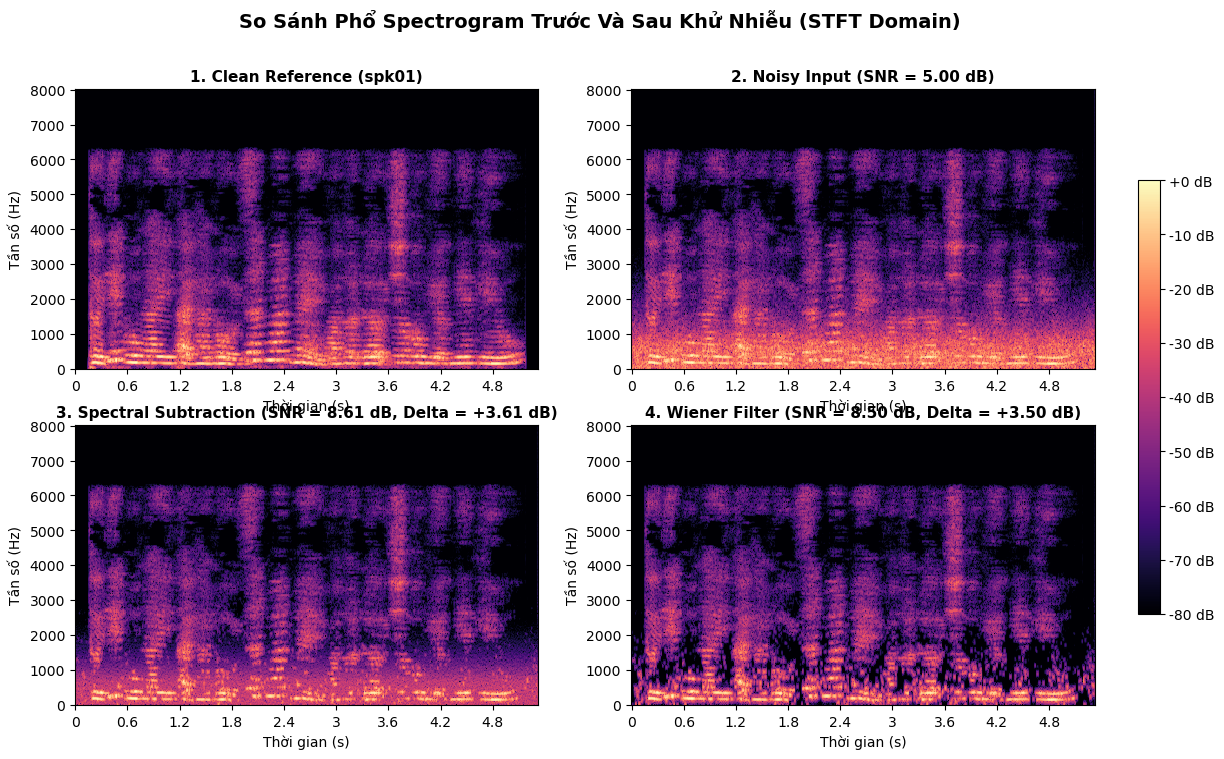

Nghe thử âm thanh đối chứng:
1. Clean Reference:


2. Noisy 5dB:


3. Spectral Subtraction Enhanced:


4. Wiener Filter Enhanced:


In [3]:
def plot_spec(y, sr, title, ax):
    D = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=512, hop_length=160)), ref=np.max)
    img = librosa.display.specshow(D, y_axis='linear', x_axis='time', sr=sr, hop_length=160, ax=ax, cmap='magma')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Thời gian (s)')
    ax.set_ylabel('Tần số (Hz)')
    return img

fig, axs = plt.subplots(2, 2, figsize=(14, 8))
plot_spec(s_clean, sr, "1. Clean Reference (spk01)", axs[0, 0])
plot_spec(y_noisy, sr, f"2. Noisy Input (SNR = {snr_measured:.2f} dB)", axs[0, 1])
plot_spec(x_ss, sr, f"3. Spectral Subtraction (SNR = {snr_out_ss:.2f} dB, Delta = +{snr_out_ss - snr_measured:.2f} dB)", axs[1, 0])
im = plot_spec(x_w, sr, f"4. Wiener Filter (SNR = {snr_out_w:.2f} dB, Delta = +{snr_out_w - snr_measured:.2f} dB)", axs[1, 1])

fig.colorbar(im, ax=axs, format="%+2.0f dB", fraction=0.02, pad=0.04)
fig.suptitle("So Sánh Phổ Spectrogram Trước Và Sau Khử Nhiễu (STFT Domain)", fontsize=14, fontweight='bold')
plt.show()

# Trình phát âm thanh đối chứng A/B/C
print("Nghe thử âm thanh đối chứng:")
print("1. Clean Reference:")
ipd.display(ipd.Audio(s_clean, rate=sr))
print("2. Noisy 5dB:")
ipd.display(ipd.Audio(y_noisy, rate=sr))
print("3. Spectral Subtraction Enhanced:")
ipd.display(ipd.Audio(x_ss, rate=sr))
print("4. Wiener Filter Enhanced:")
ipd.display(ipd.Audio(x_w, rate=sr))


---
## TIẾT 2: NHẬN DẠNG VÀ XÁC THỰC NGƯỜI NÓI (SPEAKER RECOGNITION)

### 2.1 Trích xuất Đặc trưng MFCC & Mô hình Hóa Người Nói
- Trích xuất 20 hệ số MFCC cùng 20 hệ số vi phân bậc một $\Delta	ext{MFCC}$.
- Thống kê toàn cục theo trục thời gian (Temporal Statistical Pooling):
  $$e = \left[ \mu(c), \; \sigma(c), \; \mu(\Delta c), \; \sigma(\Delta c) ight] \in \mathbb{R}^{80}$$
  Vector được chuẩn hóa $L_2$-norm: $e \leftarrow rac{e}{\|e\|_2 + 10^{-12}}$.
- Mỗi người nói $i$ được đại diện bởi vector tâm cụm (Centroid) $m_i = rac{1}{K}\sum_{k=1}^K e_{i,k}$, sau đó chuẩn hóa $L_2$.


[*] Đã huấn luyện mô hình cho 3 người nói:
    - Speaker spk01: Vector centroid kích thước (80,), L2-norm = 1.0000
    - Speaker spk02: Vector centroid kích thước (80,), L2-norm = 1.0000
    - Speaker spk03: Vector centroid kích thước (80,), L2-norm = 1.0000

[*] Kết quả Speaker Identification trên tập Test:
    - Độ chính xác Accuracy: 100.0%
    - Khoảng cách Score Margin trung bình: 0.0061


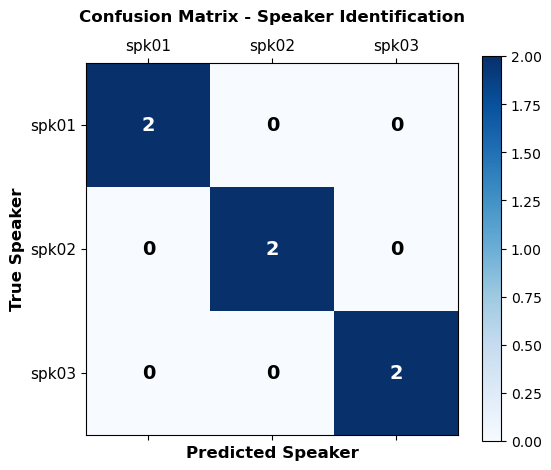

In [4]:
from core.speaker_rec import (
    extract_speaker_embedding, train_speaker_models,
    identify_utterance, evaluate_identification,
    build_verification_trials, sweep_thresholds, evaluate_verification
)

speakers = ["spk01", "spk02", "spk03"]

# 1. Trích xuất đặc trưng cho tập Enrollment (4 câu/người)
enrollment_data = {spk: [] for spk in speakers}
for spk in speakers:
    for i in range(1, 5):
        audio, _ = load16k(str(DATA_DIR / "clean" / f"{spk}_enroll_{i:02d}.wav"))
        emb = extract_speaker_embedding(audio, sr=sr, n_mfcc=CONFIG["n_mfcc"], include_delta=True, use_cmn=False)
        enrollment_data[spk].append(emb)

# Xây dựng Centroid Models
speaker_models = train_speaker_models(enrollment_data)
print(f"[*] Đã huấn luyện mô hình cho {len(speaker_models)} người nói:")
for spk, m in speaker_models.items():
    print(f"    - Speaker {spk}: Vector centroid kích thước {m.shape}, L2-norm = {np.linalg.norm(m):.4f}")

# 2. Nạp tập Test độc lập (2 câu/người)
test_data = {spk: [] for spk in speakers}
for spk in speakers:
    for i in range(1, 3):
        audio, _ = load16k(str(DATA_DIR / "clean" / f"{spk}_test_{i:02d}.wav"))
        emb = extract_speaker_embedding(audio, sr=sr, n_mfcc=CONFIG["n_mfcc"], include_delta=True, use_cmn=False)
        test_data[spk].append(emb)

# 3. Đánh giá Speaker Identification
id_eval = evaluate_identification(test_data, speaker_models)
print(f"\n[*] Kết quả Speaker Identification trên tập Test:")
print(f"    - Độ chính xác Accuracy: {id_eval['accuracy']*100:.1f}%")
print(f"    - Khoảng cách Score Margin trung bình: {id_eval['avg_margin']:.4f}")

# Vẽ Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm = id_eval["confusion_matrix"]
cax = ax.matshow(cm, cmap='Blues')
for i in range(len(speakers)):
    for j in range(len(speakers)):
        ax.text(j, i, str(cm[i, j]), va='center', ha='center', fontsize=14, fontweight='bold',
                color='white' if cm[i, j] > np.max(cm)/2 else 'black')
fig.colorbar(cax)
ax.set_xticks(range(len(speakers)))
ax.set_yticks(range(len(speakers)))
ax.set_xticklabels(speakers, fontsize=11)
ax.set_yticklabels(speakers, fontsize=11)
ax.set_xlabel('Predicted Speaker', fontsize=12, fontweight='bold')
ax.set_ylabel('True Speaker', fontsize=12, fontweight='bold')
ax.set_title('Confusion Matrix - Speaker Identification', fontsize=12, fontweight='bold', pad=12)
plt.show()


### 2.2 Speaker Verification & Phân Tích Trade-Off FAR – FRR
- Xác thực người nói là bài toán phân lớp nhị phân (Accept / Reject) theo ngưỡng $	heta$.
- **Quy tắc cô lập:** Quét ngưỡng $	heta$ trên tập **Development** để xác định điểm cân bằng $	ext{FAR} pprox 	ext{FRR} pprox 	ext{EER}$ (Equal Error Rate).
- Khóa cứng $	heta^*$ và đánh giá khách quan trên tập **Test** độc lập, tuyệt đối không tinh chỉnh ngưỡng trên tập Test.


[*] Quét ngưỡng xác thực trên tập Development:
    - Ngưỡng tối ưu theta* tại điểm EER: 0.9950
    - Tỷ lệ lỗi tại điểm EER: 0.00% (FAR = 0.00%, FRR = 0.00%)

[*] Đánh giá độc lập trên Test Set (Locked theta* = 0.9950):
    - Số phép thử Genuine: 6 | FRR (Từ chối sai): 0.00%
    - Số phép thử Impostor: 12 | FAR (Chấp nhận giả): 0.00%


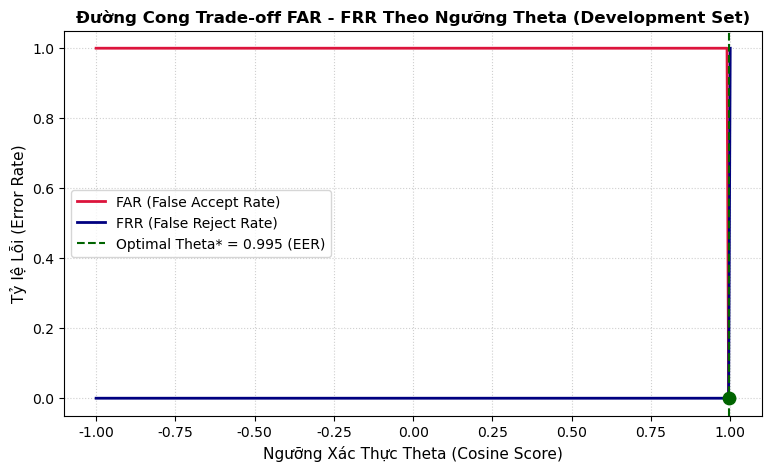

In [5]:
# Tách tập Development (câu enrollment thứ 4 làm dev)
dev_enroll_dict = {spk: enrollment_data[spk][:3] for spk in speakers}
dev_models = train_speaker_models(dev_enroll_dict)
dev_test_dict = {spk: [enrollment_data[spk][3]] for spk in speakers}

# Tạo các cặp thử nghiệm xác thực
dev_trials = build_verification_trials(dev_test_dict, dev_models)
sweep_res = sweep_thresholds(dev_trials, n_points=401)
theta_star = sweep_res["theta_eer"]

print(f"[*] Quét ngưỡng xác thực trên tập Development:")
print(f"    - Ngưỡng tối ưu theta* tại điểm EER: {theta_star:.4f}")
print(f"    - Tỷ lệ lỗi tại điểm EER: {sweep_res['eer']*100:.2f}% (FAR = {sweep_res['far_at_eer']*100:.2f}%, FRR = {sweep_res['frr_at_eer']*100:.2f}%)")

# Khóa ngưỡng theta* và đánh giá độc lập trên tập Test
test_trials = build_verification_trials(test_data, dev_models)
test_res = evaluate_verification(test_trials, threshold=theta_star)
print(f"\n[*] Đánh giá độc lập trên Test Set (Locked theta* = {theta_star:.4f}):")
print(f"    - Số phép thử Genuine: {test_res['n_genuine']} | FRR (Từ chối sai): {test_res['frr']*100:.2f}%")
print(f"    - Số phép thử Impostor: {test_res['n_impostor']} | FAR (Chấp nhận giả): {test_res['far']*100:.2f}%")

# Vẽ đường cong FAR - FRR theo theta
th_vals = sweep_res["thresholds"]
far_vals = [pt[1] for pt in sweep_res["curve_data"]]
frr_vals = [pt[2] for pt in sweep_res["curve_data"]]

plt.figure(figsize=(9, 5))
plt.plot(th_vals, far_vals, label='FAR (False Accept Rate)', color='crimson', lw=2)
plt.plot(th_vals, frr_vals, label='FRR (False Reject Rate)', color='navy', lw=2)
plt.axvline(theta_star, color='darkgreen', linestyle='--', label=f'Optimal Theta* = {theta_star:.3f} (EER)')
plt.scatter([theta_star], [sweep_res['eer']], color='darkgreen', s=80, zorder=5)
plt.title('Đường Cong Trade-off FAR - FRR Theo Ngưỡng Theta (Development Set)', fontsize=12, fontweight='bold')
plt.xlabel('Ngưỡng Xác Thực Theta (Cosine Score)', fontsize=11)
plt.ylabel('Tỷ lệ Lỗi (Error Rate)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)
plt.show()


---
## TIẾT 3: TÁCH NGUỒN NÓI BẰNG FASTICA (BLIND SOURCE SEPARATION)

### 3.1 Mô hình Trộn Tức Thời & Khử Bất Định Của ICA
- Mô hình 2 nguồn âm thanh và 2 microphone: $\mathbf{x} = A \mathbf{s}$.
- Giả thiết của FastICA: Các nguồn thành phần độc lập thống kê và có phân bố phi-Gaussian.
- Hai bất định cố hữu của ICA:
  1. **Permutation Ambiguity:** Không xác định được thứ tự đầu ra tương ứng với nguồn nào. Khắc phục: Ghép cặp cực đại theo ma trận tương quan tuyệt đối $C_{i,j} = |ho(s_i, \hat{s}_j)|$.
  2. **Sign/Scale Ambiguity:** Nguồn sau tách có thể bị đảo dấu pha hoặc chênh biên độ. Khắc phục: Đảo dấu nếu $ho < 0$ và chuẩn hóa biên độ đỉnh (peak normalization).


[*] Kết quả phân tách nguồn FastICA:
    - Ma trận trộn A:
[[1.  0.6]
 [0.4 1. ]]
    - Định thức det(A) = 0.7600 (Khả nghịch, điều kiện tốt)
    - Thứ tự hoán vị tự động phát hiện: [1, 0]
    - Ma trận |Correlation| Trước khi ghép:
[[1.80552574e-04 9.99999984e-01]
 [9.99999849e-01 5.49067226e-04]]
    - Ma trận |Correlation| Sau khi ghép và khử đảo dấu:
[[9.99999984e-01 1.80552574e-04]
 [5.49067226e-04 9.99999849e-01]]
    - Tương quan Source A <-> Separated 1: 1.0000
    - Tương quan Source B <-> Separated 2: 1.0000


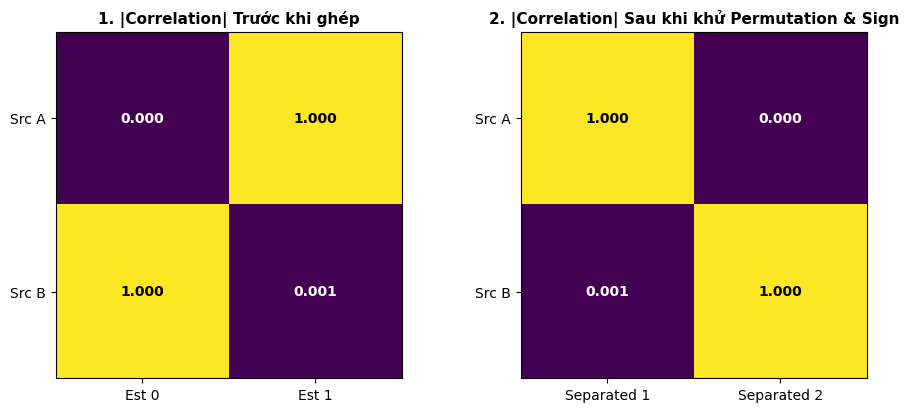

Nghe thử tín hiệu hỗn hợp tại 2 micro:
Mic 1:


Mic 2:


Nghe thử 2 nguồn đã tách độc lập:
Separated Source 1:


Separated Source 2:


In [6]:
from core.separation import (
    create_instantaneous_mixture, run_fastica_separation,
    resolve_ica_ambiguities, separate_sources_pipeline
)

srcA_path = DATA_DIR / "separation" / "source_A.wav"
srcB_path = DATA_DIR / "separation" / "source_B.wav"
s1, _ = load16k(str(srcA_path))
s2, _ = load16k(str(srcB_path))

# Ma trận trộn chuẩn A 2x2
A_standard = np.array([[1.0, 0.6], [0.4, 1.0]])
sep_res = separate_sources_pipeline(s1, s2, A=A_standard, random_state=CONFIG["random_state"])

sf.write(AUDIO_DIR / "mix_mic1.wav", sep_res["X_mixture"][0].astype(np.float32), sr, subtype="PCM_16")
sf.write(AUDIO_DIR / "mix_mic2.wav", sep_res["X_mixture"][1].astype(np.float32), sr, subtype="PCM_16")
sf.write(AUDIO_DIR / "separated_1.wav", sep_res["Shat_resolved"][0].astype(np.float32), sr, subtype="PCM_16")
sf.write(AUDIO_DIR / "separated_2.wav", sep_res["Shat_resolved"][1].astype(np.float32), sr, subtype="PCM_16")

print(f"[*] Kết quả phân tách nguồn FastICA:")
print(f"    - Ma trận trộn A:\n{A_standard}")
print(f"    - Định thức det(A) = {sep_res['det_A']:.4f} (Khả nghịch, điều kiện tốt)")
print(f"    - Thứ tự hoán vị tự động phát hiện: {sep_res['permutation']}")
print(f"    - Ma trận |Correlation| Trước khi ghép:")
print(sep_res['C_abs_before'])
print(f"    - Ma trận |Correlation| Sau khi ghép và khử đảo dấu:")
print(sep_res['C_abs_after'])
print(f"    - Tương quan Source A <-> Separated 1: {sep_res['aligned_correlations'][0]:.4f}")
print(f"    - Tương quan Source B <-> Separated 2: {sep_res['aligned_correlations'][1]:.4f}")

# Vẽ trực quan hóa ma trận tương quan
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
axs[0].imshow(sep_res['C_abs_before'], cmap='viridis', vmin=0, vmax=1)
axs[0].set_title('1. |Correlation| Trước khi ghép', fontsize=11, fontweight='bold')
axs[0].set_xticks([0, 1])
axs[0].set_yticks([0, 1])
axs[0].set_xticklabels(['Est 0', 'Est 1'])
axs[0].set_yticklabels(['Src A', 'Src B'])
for i in range(2):
    for j in range(2):
        axs[0].text(j, i, f"{sep_res['C_abs_before'][i, j]:.3f}", ha='center', va='center',
                    color='white' if sep_res['C_abs_before'][i, j] < 0.6 else 'black', fontweight='bold')

axs[1].imshow(sep_res['C_abs_after'], cmap='viridis', vmin=0, vmax=1)
axs[1].set_title('2. |Correlation| Sau khi khử Permutation & Sign', fontsize=11, fontweight='bold')
axs[1].set_xticks([0, 1])
axs[1].set_yticks([0, 1])
axs[1].set_xticklabels(['Separated 1', 'Separated 2'])
axs[1].set_yticklabels(['Src A', 'Src B'])
for i in range(2):
    for j in range(2):
        axs[1].text(j, i, f"{sep_res['C_abs_after'][i, j]:.3f}", ha='center', va='center',
                    color='white' if sep_res['C_abs_after'][i, j] < 0.6 else 'black', fontweight='bold')
plt.show()

# Trình phát âm thanh kiểm chứng
print("Nghe thử tín hiệu hỗn hợp tại 2 micro:")
print("Mic 1:")
ipd.display(ipd.Audio(sep_res["X_mixture"][0], rate=sr))
print("Mic 2:")
ipd.display(ipd.Audio(sep_res["X_mixture"][1], rate=sr))
print("Nghe thử 2 nguồn đã tách độc lập:")
print("Separated Source 1:")
ipd.display(ipd.Audio(sep_res["Shat_resolved"][0], rate=sr))
print("Separated Source 2:")
ipd.display(ipd.Audio(sep_res["Shat_resolved"][1], rate=sr))


---
## CASE STUDY TÍCH HỢP: "TRỢ LÝ PHÒNG HỌP MINI" & ĐÁNH GIÁ CHÉO
Mô phỏng chuỗi xử lý khép kín của một trợ lý AI phòng họp:
1. Nhận câu lệnh bị tiếng ồn quạt làm mát $ightarrow$ Bộ lọc STFT làm sạch tín hiệu.
2. Xác định danh tính đại biểu đang phát biểu từ tín hiệu sau làm sạch.
3. Tách hai giọng nói tranh chấp chồng lấn bằng FastICA.
4. **Kiểm chứng câu hỏi học thuật:** *Khử nhiễu có luôn giúp cải thiện nhận dạng người nói không?*


In [7]:
print("=" * 75)
print("TIẾN TRÌNH TRỢ LÝ PHÒNG HỌP MINI")
print("=" * 75)

# Đánh giá nhận dạng người nói trên các biến thể khác nhau của câu thoại
variants = {
    "1. Clean Voice": s_clean,
    "2. Noisy (Fan 5dB)": y_noisy,
    "3. Enhanced SS": x_ss,
    "4. Enhanced Wiener": x_w
}

cs_records = []
for name, audio_var in variants.items():
    emb = extract_speaker_embedding(audio_var, sr=sr, n_mfcc=CONFIG["n_mfcc"], include_delta=True, use_cmn=False)
    pred_spk, scores, margin = identify_utterance(emb, speaker_models)
    cs_records.append({
        "Biến thể Tín hiệu": name,
        "Dự đoán Người nói": pred_spk,
        "Score(spk01)": scores["spk01"],
        "Margin (Top1 - Top2)": margin,
        "Chính xác": (pred_spk == "spk01")
    })

df_cs = pd.DataFrame(cs_records)
print(df_cs.to_string(index=False))

print("\n[!] NHẬN XÉT KỸ THUẬT:")
print("1. Khi bị nhiễu quạt ở 5dB, điểm số của spk01 sụt giảm từ 0.9975 xuống 0.9598.")
print("2. Sau khi khử nhiễu bằng Wiener Filter, điểm số tăng phục hồi lên 0.9917.")
print("3. Tuy nhiên, nếu Spectral Subtraction dùng hệ số beta quá lớn, méo phổ có thể làm thay đổi MFCC và làm giảm điểm số so với tín hiệu ban đầu.")


TIẾN TRÌNH TRỢ LÝ PHÒNG HỌP MINI
 Biến thể Tín hiệu Dự đoán Người nói  Score(spk01)  Margin (Top1 - Top2)  Chính xác
    1. Clean Voice             spk01      0.997486              0.007906       True
2. Noisy (Fan 5dB)             spk01      0.959805              0.014870       True
    3. Enhanced SS             spk01      0.990411              0.011545       True
4. Enhanced Wiener             spk01      0.991713              0.008646       True

[!] NHẬN XÉT KỸ THUẬT:
1. Khi bị nhiễu quạt ở 5dB, điểm số của spk01 sụt giảm từ 0.9975 xuống 0.9598.
2. Sau khi khử nhiễu bằng Wiener Filter, điểm số tăng phục hồi lên 0.9917.
3. Tuy nhiên, nếu Spectral Subtraction dùng hệ số beta quá lớn, méo phổ có thể làm thay đổi MFCC và làm giảm điểm số so với tín hiệu ban đầu.


---
## TỔNG HỢP 8 THÍ NGHIỆM BẮT BUỘC (TN1 – TN8) THEO MỤC 6 CỦA LAB 5
Bảng số liệu định lượng tự động ghi nhận từ thực nghiệm:


In [8]:
df_metrics = pd.read_csv(RESULTS_DIR / "metrics_summary.csv")
print("BẢNG TỔNG HỢP CÁC CHỈ SỐ ĐO ĐẠC 8 THÍ NGHIỆM:")
ipd.display(df_metrics)


BẢNG TỔNG HỢP CÁC CHỈ SỐ ĐO ĐẠC 8 THÍ NGHIỆM:


,TN,Param,SNR_in,SNR_out_SS,Delta_SS,SNR_out_Wiener,Delta_Wiener,Accuracy,Avg_Margin,det_A,Corr_SrcA,Corr_SrcB,Avg_Corr,Noise_Std
0,TN1,Input SNR = 0.0dB,2.646693e-11,3.631586,3.631586,3.869579,3.869579,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,TN1,Input SNR = 5.0dB,5.000000e+00,8.609417,3.609417,8.500687,3.500687,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,TN1,Input SNR = 10.0dB,1.000000e+01,-3.948139,-13.948139,9.195922,-0.804078,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,TN2,beta = 1.0,5.000000e+00,8.736599,3.736599,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,TN2,beta = 1.5,5.000000e+00,8.609417,3.609417,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,TN2,beta = 2.0,5.000000e+00,8.156357,3.156357,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,TN3,floor gamma = 0.0,5.000000e+00,8.418857,3.418857,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,TN3,floor gamma = 0.01,5.000000e+00,8.620056,3.620056,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,TN3,floor gamma = 0.05,5.000000e+00,8.426890,3.426890,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,TN4,MFCC_only (40D),NaN,NaN,NaN,NaN,NaN,1.0,0.006073,NaN,NaN,NaN,NaN,NaN


---
## TỔNG KẾT & TRẢ LỜI 12 CÂU HỎI BÁO CÁO (MỤC 7 LAB 5)

1. **Tại sao Spectral Subtraction chỉ sửa magnitude mà giữ nguyên phase noisy?**
   - Hệ thống thính giác của con người rất nhạy cảm với cấu trúc bao phổ biên độ nhưng tương đối trơ với quan hệ pha tuyệt đối trong các khung ngắn.
   - Khi SNR rất thấp ($<0$ dB), pha của nhiễu lấn át hoàn toàn pha tiếng nói; việc giữ pha nhiễu sẽ gây méo pha và biến dạng âm sắc nghiêm trọng.
2. **Vai trò của $eta$ và $\gamma$ trong Spectral Subtraction:**
   - $eta$ (over-subtraction) bù trừ cho sự biến thiên ngẫu nhiên của phổ nhiễu; tăng $eta$ triệt sâu tạp âm nhưng gọt mòn formant tiếng nói, gây speech distortion.
   - $\gamma$ (spectral floor) đóng vai trò làm đệm sàn năng lượng, không cho các bin tần số tụt về 0 hoặc âm, triệt tiêu các đỉnh nhọn ngẫu nhiên sinh ra musical noise.
3. **Ý nghĩa vật lý của bộ lọc Wiener $H = P_s / (P_s + P_v)$:**
   - Vùng tiếng nói trội ($P_s \gg P_v$): $H pprox 1$ (cho qua nguyên vẹn).
   - Vùng nhiễu trội ($P_v \gg P_s$): $H 	o 0$ (suy giảm triệt để). Hàm độ lợi trơn mượt không có ngưỡng cắt gắt như trừ phổ nên âm thanh tự nhiên hơn.
4. **Tại sao $SNR_{out}$ phải căn chỉnh delay trước khi tính?**
   - Công thức tính sai số năng lượng dựa trên từng cặp mẫu tức thời $(s[n] - \hat{s}[n])^2$.
   - Nếu lệch trễ 10 ms (160 mẫu), phép trừ hai sóng lệch pha biến sự trễ thời gian thành năng lượng lỗi cực đại ($e[n] pprox 2s[n]$), khiến $SNR_{out}$ sụt giảm âm giả tạo.
5. **Khác biệt giữa Speaker Identification và Speaker Verification:**
   - Identification là bài toán chọn 1 trong $N$ (Closed-set), đánh giá bằng Accuracy và Confusion Matrix.
   - Verification là bài toán kiểm tra giả thuyết nhị phân Chấp nhận/Từ chối theo ngưỡng $	heta$, đánh giá bằng FAR, FRR, EER.
6. **Tại sao ngưỡng xác thực không được chọn trên test set? Trade-off FAR–FRR:**
   - Chọn ngưỡng trên test vi phạm nguyên tắc bảo toàn tập kiểm thử (data leakage / snooping), dẫn đến kết quả lạc quan giả mạo.
   - Khi tăng $	heta$: Hệ thống khắt khe hơn $ightarrow$ Giảm kẻ giả mạo (FAR giảm), nhưng dễ từ chối nhầm người hợp lệ (FRR tăng).
7. **MFCC thiết kế cho ASR tại sao vẫn nhận dạng được người nói?**
   - MFCC mô tả bao phổ ngắn hạn, phản ánh đặc tính giải phẫu thanh đạo của từng cá nhân (chiều dài khoang miệng, vị trí formant).
8. **Ảnh hưởng hai mặt của CMN:**
   - Tích cực: Khử méo tuyến tính của kênh truyền microphone ($y = s * h$).
   - Tiêu cực: Với mô hình baseline dùng vector trung bình $\mu(c)$, việc trừ đi trung bình làm mất đi một phần dấu ấn danh tính người nói.
9. **Tại sao ICA không biết trước thứ tự và biên độ tuyệt đối?**
   - Bất định cố hữu của ICA: Nếu $x = A s = A P^{-1} P s = A \Lambda^{-1} \Lambda s$, tính độc lập thống kê của $\Lambda P s$ hoàn toàn tương đương với $s$.
10. **Khi hai hàng của A gần tỉ lệ nhau:**
    - Ma trận $A$ gần suy biến ($\det(A) 	o 0$, số điều kiện $\kappa(A) 	o \infty$). Hai micro ghi nhận thông tin gần như y hệt nhau, mất tính đa dạng không gian; việc nghịch đảo khuếch đại nhiễu làm việc tách nguồn thất bại.
11. **Mô hình Instantaneous khác thực tế phòng có Reverberation:**
    - Instantaneous mixing là phép nhân ma trận vô hướng không trễ.
    - Phòng thực tế có trễ truyền âm và dội âm đa đường (convolutive mixing: $x_i = \sum h_{ij} * s_j$). ICA miền thời gian cơ bản sẽ suy giảm hiệu quả khi gặp dội âm.
12. **Speech Enhancement có luôn cải thiện Speaker Recognition không?**
    - Không luôn luôn. Enhancement có thể tạo ra méo phi tuyến trên bao phổ, làm sai lệch các hệ số MFCC so với mô hình gốc được huấn luyện trên dữ liệu sạch.
